In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import cartopy.crs as ccrs
from pathlib import Path

In [2]:
ROOT = Path.cwd().parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
FEATURE_DIR = RESULTS / "features"

In [3]:
world_map_ = gpd.read_file(DATA / 'simplified-world-map/world-map.shp')
world_map_['geometry'] = world_map_.buffer(0)
world_map = world_map_.drop([31])
world_map = world_map.to_crs('ESRI:54012')

In [4]:
country_raster_1km_  = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-1km.tif')

In [5]:
global_mining_suitability_1km = rio.open(RESULTS / 'global-mining-suitability-1km.tif').read(1)

pred_class = np.zeros(global_mining_suitability_1km.shape, dtype=np.uint8)
mask = global_mining_suitability_1km > 0
clipped = np.clip(global_mining_suitability_1km[mask], 1, 10000)
pred_class[mask] = (clipped // 1000).astype(np.uint8) + 1
pred_class[pred_class > 10] = 10

In [6]:
cmap = ListedColormap(["white", "blue", "red"])
cmap2 = plt.get_cmap("RdYlBu_r", 10)
display_extent_1km = [country_raster_1km_.bounds.left, country_raster_1km_.bounds.right, country_raster_1km_.bounds.bottom, country_raster_1km_.bounds.top]
norm = BoundaryNorm(boundaries=np.arange(0.5, 11.5, 1), ncolors=cmap2.N)

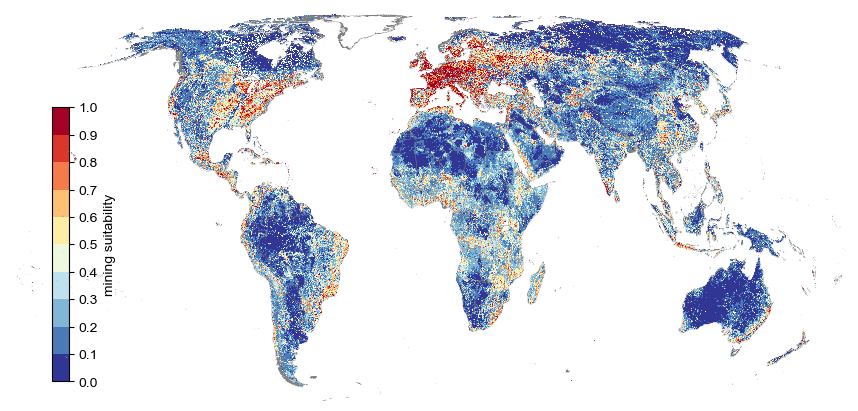

In [7]:
fig = plt.figure(figsize=(8.5, 4), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial' 

ax1 = plt.subplot(111, projection=ccrs.EckertIV())
world_map.plot(color='none', edgecolor='grey', lw=0.2, ax=ax1, zorder=10)
im1 = ax1.imshow(np.where(pred_class > 0, pred_class, np.nan), cmap=cmap2, norm=norm, interpolation='nearest', extent=display_extent_1km, zorder=5)
ax1.set_ylim(-7.2e6, 8.6e6)
ax1.axis('off')
cax1_1 = ax1.inset_axes([0.05, 0.05, 0.02, 0.70])
ticks = np.arange(0.5, 11.5, 1)
labels = [f"{i/10:.1f}" for i in range(0, 11)]  # 0.0 ... 1.0
cbar2_1 = fig.colorbar(im1, cax=cax1_1, orientation='vertical', ticks=ticks, label='mining suitability')
cbar2_1.ax.set_yticklabels(labels)

plt.show()

In [8]:
fig.savefig(FIGURES / 'Extended-Data-Figure-3.jpg', dpi=600, bbox_inches='tight')

In [ ]:
# fig.savefig(FIGURES / 'Extended-Data-Figure-3.pdf', dpi=600, bbox_inches='tight')